# H1. Одна модель на всех — результаты

## Сокращения, аббревиатуры и метрики

| Как написано | Расшифровка |
|---|---|
| **H1** | гипотеза 1: одна общая модель лучше модели только на этой семье. |
| **десятка**, top-10 | первые 10 продуктов в списке кандидатов. |
| **Recall@10** | полнота десятки внутри семьи, затем среднее по семьям. Каждая семья весит одинаково. |
| **личная модель** | CatBoost только на покупках этой семьи, с нуля. |
| **общая модель** | один CatBoost на всех семьях. Частота этой семьи в признаках уже есть. |
| **лучше** | низ 95% интервала «общая − личная» строго выше нуля. |
| **поправка** | общая плюс добавка по семье. Предыдущая постановка, в вердикт H1 не входит. |
| **CI**, 95% интервал | бутстреп по семьям, 2000 повторов, семя 42. |
| **seed / семя** | 42: генератор учебной базы, CatBoost и бутстреп. |
| **CatBoost** | градиентный бустинг на деревьях с категориями. |
| **SQLite**, `fridge_lab` | 200 учебных семей, семя генератора 42. |

Гипотеза: общая модель угадывает десятку **лучше**, чем модель только на этой семье.

Ноутбук **не учит** модели. Он читает `данные/метрики/`. Повтор обучения — `код/personal_h1.py` на `fridge_lab.sqlite`. Вердикт без обучения — `код/eval_h1.py`.

Порядок этапов:
1. пути и сводная таблица;
2. официальный результат, семя 42;
3. каждая семья — точка;
4. короткая история;
5. что в столбцах csv.

## Этап 1. Пути и сводная таблица

Читаем `результаты/recall10.csv`. Строка — одна база, не один поход.

- **только_семья** — CatBoost на строках этой семьи.
- **общая** — один CatBoost на всех семьях.
- **прирост** — разница Recall@10, среднее по 200 семьям. Общая лучше, если низ интервала > 0. Семя 42.

Поправка к общей модели в таблицу вердикта не входит. «Лучше на 0,02» — другая постановка, сюда не входит.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

HERE = Path.cwd()
if not (HERE / "результаты").is_dir():
    HERE = Path(".").resolve()
RESULTS = HERE / "результаты"
DATA = HERE / "данные" / "метрики"

pd.read_csv(RESULTS / "recall10.csv")

база,семей,только_семья,общая,прирост,низ_CI,верх_CI,вердикт
200 семей семя 42,200,0.612,0.625,0.013,0.009,0.018,подтверждена


## Этап 2. Официальный результат, семя 42

200 семей. Только эта семья: 0,612. Общая: 0,625. Прирост **+0,013**. Красная черта — уровень личной: общая лучше, если выше.

Интервал [0,009; 0,018] целиком выше нуля. Вердикт — лучше, подтверждена.

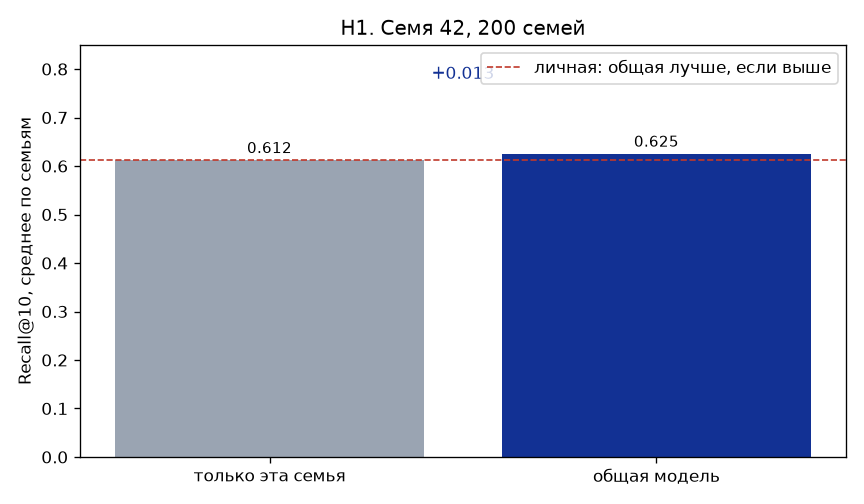

In [2]:
# Сводка для защиты: одна база, семя 42, лучше если низ > 0.
display(Image(str(RESULTS / 'recall10_сравнение.png'), width=720))

## Этап 3. Каждая семья — точка

По горизонтали — модель только на этой семье. По вертикали — общая. Выше диагонали общая выиграла.

134 семьи из 200 выше диагонали. Есть семьи, где своя модель лучше: гипотеза смотрит среднее, не «всем одинаково».

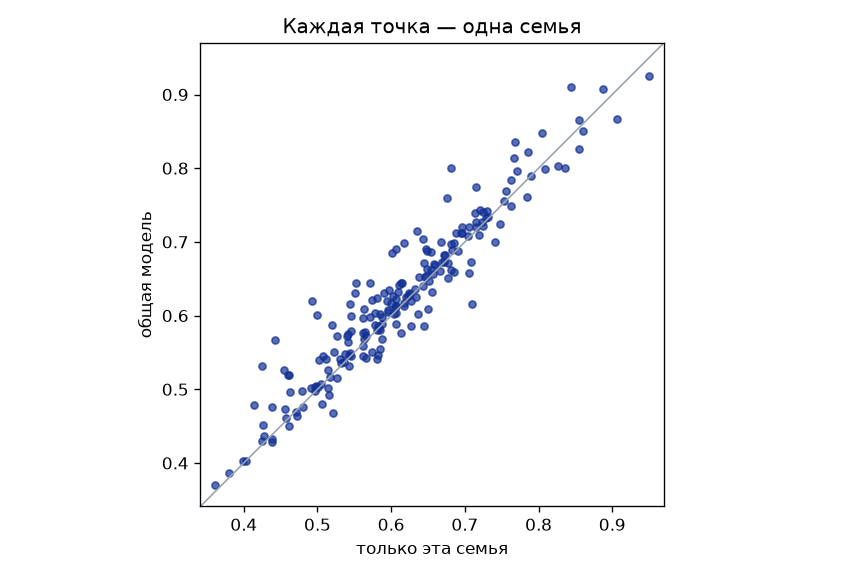

In [3]:
# Точка — семья. Диагональ — равенство двух способов.
display(Image(str(RESULTS / 'personal_vs_global.png'), width=720))

## Этап 4. Короткая история

У 40 семей историю обрезали до 3, 4, 6, 8 и 16 недель. Модель только на семье на короткой истории слабее. Общая видит всех и почти не падает.

На полной истории общая тоже не ниже. График — не вердикт, а пояснение, почему учить только на семье рано.

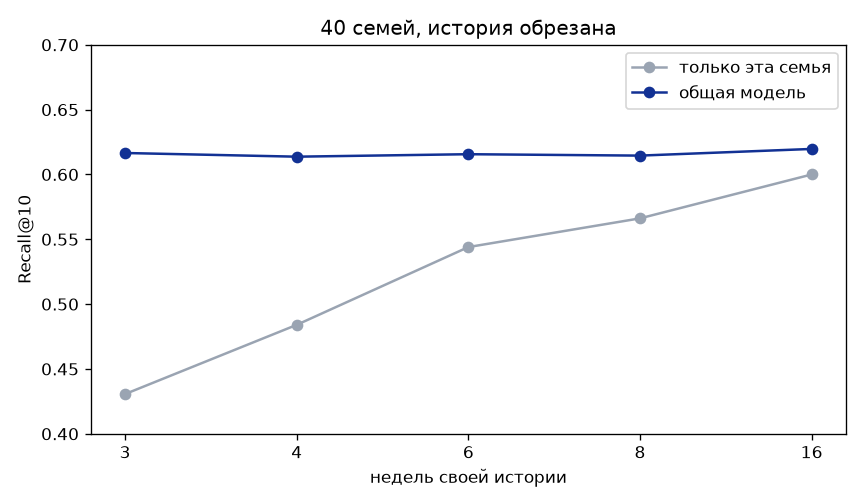

In [4]:
# 40 семей: своя история обрезана, общая модель видит всех.
display(Image(str(RESULTS / 'history_length.png'), width=720))

## Этап 5. Что в csv семей

В `forecast_v2_households.csv` каждая строка — семья. Для H1 нужны столбцы «Личная модель» и «Общая модель», метрика Recall@10.

| Столбец | Роль в H1 |
|---|---|
| Личная модель | база: только эта семья |
| Общая модель | вариант гипотезы |
| Общая + личная поправка | предыдущая постановка, в критерий не входит |
| Частота | правило H1, сюда не сравниваем |
| Личная + похожие | другая постановка, не H1 |

Ниже — первые пять семей, только столбцы вердикта.

In [5]:
# Первые семьи. Полный файл — данные/метрики/forecast_v2_households.csv.
pd.read_csv(RESULTS / "households_head.csv")

семья,только_семья,общая
1,0.622770,0.626242
2,0.771170,0.796715
3,0.695476,0.712143
4,0.677227,0.671379
5,0.425355,0.531367
